In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from xgboost import XGBClassifier

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

df = pd.read_csv(r"C:\Users\kvspp\Downloads\aiml project\ai4i+2020+predictive+maintenance+dataset\ai4i2020.csv")

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [4]:
# Select only the two important features identified by SHAP

X = df[["Torque [Nm]", "Tool wear [min]"]].copy()

y = df["Machine failure"]

print("Selected Features:")
print(X.columns.tolist())

print("\nX shape:", X.shape)
print("y shape:", y.shape)

Selected Features:
['Torque [Nm]', 'Tool wear [min]']

X shape: (10000, 2)
y shape: (10000,)


In [5]:
print(X.describe())

        Torque [Nm]  Tool wear [min]
count  10000.000000     10000.000000
mean      39.986910       107.951000
std        9.968934        63.654147
min        3.800000         0.000000
25%       33.200000        53.000000
50%       40.100000       108.000000
75%       46.800000       162.000000
max       76.600000       253.000000


In [6]:
print("Machine Failure Distribution:")
print(y.value_counts())

print("\nPercentage:")
print(y.value_counts(normalize=True) * 100)

Machine Failure Distribution:
Machine failure
0    9661
1     339
Name: count, dtype: int64

Percentage:
Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64


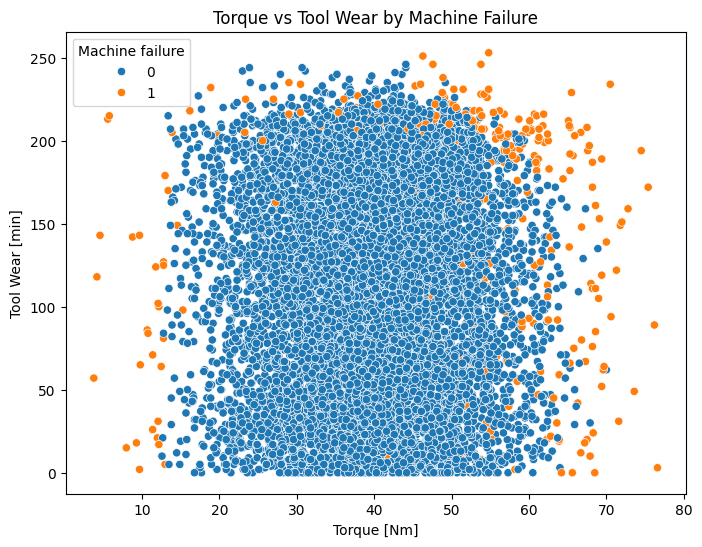

In [7]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x="Torque [Nm]",
    y="Tool wear [min]",
    hue="Machine failure"
)

plt.title("Torque vs Tool Wear by Machine Failure")
plt.xlabel("Torque [Nm]")
plt.ylabel("Tool Wear [min]")
plt.show()

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 8000
Testing samples: 2000


In [9]:
negative = (y_train == 0).sum()
positive = (y_train == 1).sum()

scale_pos_weight = negative / positive

print("Normal samples:", negative)
print("Failure samples:", positive)
print("Scale Pos Weight:", scale_pos_weight)

Normal samples: 7729
Failure samples: 271
Scale Pos Weight: 28.52029520295203


In [12]:
# Cell 8 — Train XGBoost using ONLY Torque and Tool Wear

# Make safe copies of the training and testing data
X_train_xgb = X_train.copy()
X_test_xgb = X_test.copy()

# Clean column names for XGBoost
X_train_xgb.columns = ["Torque_Nm", "Tool_wear_min"]
X_test_xgb.columns = ["Torque_Nm", "Tool_wear_min"]

# Create XGBoost model
xgb_model_2features = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42
)

# Train the model
xgb_model_2features.fit(X_train_xgb, y_train)

print("XGBoost training completed successfully!")
print("Features used:")
print("1. Torque [Nm]")
print("2. Tool wear [min]")

XGBoost training completed successfully!
Features used:
1. Torque [Nm]
2. Tool wear [min]


In [13]:
y_pred = xgb_model_2features.predict(X_test_xgb)
y_prob = xgb_model_2features.predict_proba(X_test_xgb)[:, 1]

print("Predictions generated successfully!")
print("\nFirst 10 failure probabilities:")
print(y_prob[:10])

Predictions generated successfully!

First 10 failure probabilities:
[0.9716329  0.00352277 0.78121376 0.12581195 0.66018885 0.00363862
 0.13004695 0.13697413 0.0138114  0.46364394]


In [14]:
# Cell 10 — Evaluate the two-feature XGBoost model

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print("===== TWO-FEATURE XGBOOST RESULTS =====")
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")
print(f"ROC-AUC   : {roc_auc:.4f}")

===== TWO-FEATURE XGBOOST RESULTS =====
Accuracy  : 0.8920
Precision : 0.1942
Recall    : 0.6912
F1 Score  : 0.3032
ROC-AUC   : 0.8628


In [15]:
print(classification_report(
    y_test,
    y_pred,
    target_names=["Normal", "Failure"]
))

              precision    recall  f1-score   support

      Normal       0.99      0.90      0.94      1932
     Failure       0.19      0.69      0.30        68

    accuracy                           0.89      2000
   macro avg       0.59      0.80      0.62      2000
weighted avg       0.96      0.89      0.92      2000



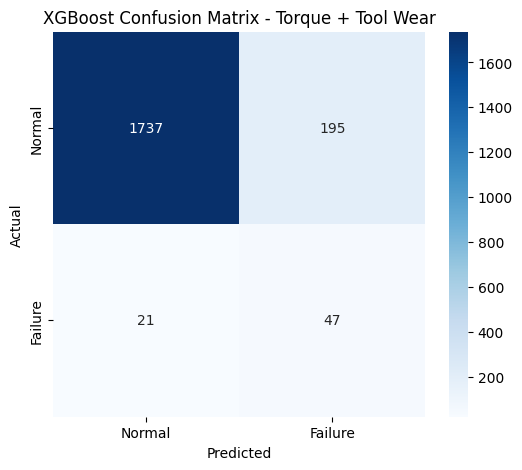

In [16]:
# Cell 11 — Confusion Matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Failure"],
    yticklabels=["Normal", "Failure"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("XGBoost Confusion Matrix - Torque + Tool Wear")

plt.show()

In [17]:
# Cell 12 — SHAP for the two-feature XGBoost model

import shap

explainer_2features = shap.TreeExplainer(xgb_model_2features)

shap_values_2features = explainer_2features.shap_values(X_test_xgb)

print("SHAP values generated successfully!")
print("SHAP shape:", shap_values_2features.shape)

C:\Users\kvspp\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SHAP values generated successfully!
SHAP shape: (2000, 2)


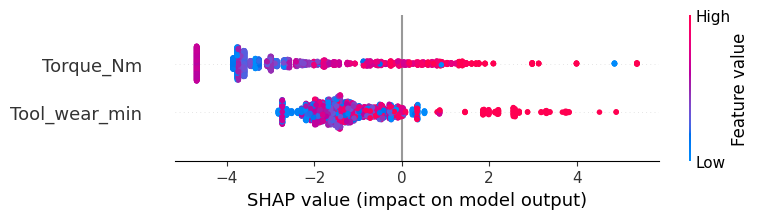

In [18]:
# SHAP Summary Plot — Torque + Tool Wear

shap.summary_plot(
    shap_values_2features,
    X_test_xgb
)